# Motif Schur Decomposition Analysis

This notebook is the motif-level companion to the existing Schur decomposition workflow. It decomposes each exported 3x3 motif subnetwork, compares blocks with and without stored self-weights, and ranks motifs by local Schur-mode strength and non-normal triangular coupling.

> **Corrections pass 2026-09-17.** Two changes, both in
> `motif_schur_decomposition_analysis_script.py`.
>
> 1. **Pinned diagonal order.** `scipy.linalg.schur` promises nothing about the
>    order of the eigenvalues along `T`'s diagonal, and the order is free under
>    the decomposition -- but it is not free for the statistics reported here.
>    `|T[m, m+1:]|.sum()` sums the entries above the diagonal in row `m`, so
>    which modes count as "later", and therefore the whole per-mode cascade
>    profile, depends entirely on that order; on this motif set the maximum of
>    that quantity moves between orders, and `dominant_schur_node` and the
>    greedy-tree attribution move with it. The convention adopted is
>    **descending Re(lambda)**, ties broken by descending `|lambda|` then
>    descending `Im(lambda)`, applied in the module so every table inherits it.
>
> 2. **Direction label.** `schur_upper_coupling_out_abs` is now
>    `schur_upper_coupling_in_abs` (and `upper_triangular_coupling_out_abs` is
>    `..._in_abs`). Blocks are analysed as `[post, pre]`, so `dy/dt = T y` gives
>    `(T y)_m = sum_k T[m, k] y_k`: row `m` is drive *into* mode `m`. The
>    quantity is the coupling a mode **receives** from later modes, not the
>    coupling it sends.
>
> Neither change touches the basis-independent quantities. `schur_offdiag_norm`
> (the Henrici departure), `schur_departure_ratio`, the eigenvalues as a set and
> `spectral_radius` are invariant under both, as is `T` itself under cell-type
> reordering (an orthogonal similarity, verified to 5.8e-14).


## Configuration

The inputs are the Schur-ready 3x3 subnetwork exports produced by `motif_pathway_analysis.ipynb`. Those exports are source-to-target blocks: rows are presynaptic/source cell types and columns are postsynaptic/target cell types. This notebook transposes each 3x3 block once after loading, so all Schur/eigen analyses use the same convention as the global notebooks: rows are postsynaptic targets and columns are presynaptic sources.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import motif_schur_decomposition_analysis_script as analysis

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 180)

INPUT_DIR=Path("outputs/motif_pathway_analysis")
OUTPUT_DIR=Path("outputs/motif_schur_decomposition_analysis"); OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

NO_SELF_CSV=INPUT_DIR/"schur_ready_3x3_subnetworks_without_self.csv"
NO_SELF_NPZ=INPUT_DIR/"schur_ready_3x3_subnetworks_without_self.npz"
WITH_SELF_CSV=INPUT_DIR/"schur_ready_3x3_subnetworks_with_self.csv"
WITH_SELF_NPZ=INPUT_DIR/"schur_ready_3x3_subnetworks_with_self.npz"

MOTIF_INDEX_MATRIX_WEIGHT="spectral_radius"
MOTIF_INDEX_N_MODES=12
MOTIF_INDEX_NORMALIZE_ROWS=False

TRANSPOSE_SOURCE_TARGET_BLOCKS=True


MOTIF_ACTIVATION_GAIN=0.50



## Load motif subnetwork blocks

This section checks that the metadata rows and 3x3 arrays are aligned. The no-self block set supports motif-only Schur analysis, while the with-self block set shows how the diagonal terms alter the same local motif modes.

In [2]:
meta_no,blocks_no=analysis.load_schur_blocks(NO_SELF_CSV,NO_SELF_NPZ)
meta_self,blocks_self=analysis.load_schur_blocks(WITH_SELF_CSV,WITH_SELF_NPZ)
if TRANSPOSE_SOURCE_TARGET_BLOCKS:
    blocks_no=blocks_no.transpose(0,2,1)
    blocks_self=blocks_self.transpose(0,2,1)
BLOCK_ORIENTATION="rows=postsynaptic target, columns=presynaptic source"
all_cell_types=pd.concat([meta_no[["node_1","node_2","node_3"]].stack(),meta_self[["node_1","node_2","node_3"]].stack()],ignore_index=True)
acronym_map=analysis.make_acronym_map(all_cell_types)
acronyms=analysis.acronym_table(acronym_map)
print("without self metadata/block shape:",meta_no.shape,blocks_no.shape)
print("with self metadata/block shape:",meta_self.shape,blocks_self.shape)
print("block orientation used for analysis:",BLOCK_ORIENTATION)
print("cell-type acronyms:",len(acronyms))
display(acronyms.head(25))
display(analysis.add_acronym_columns(meta_no.head(10),acronym_map))


without self metadata/block shape: (2000, 21) (2000, 3, 3)
with self metadata/block shape: (2000, 21) (2000, 3, 3)
block orientation used for analysis: rows=postsynaptic target, columns=presynaptic source
cell-type acronyms: 85


,cell_type,cell_type_acronym
0,CA1 Axo Axonic,CA1-AxAxo
1,CA1 Back Projection,CA1-BackProj
2,CA1 Basket,CA1-Bas
3,CA1 Basket CCK+,CA1-BasCCK
4,CA1 Bistratified,CA1-Bi
5,CA1 Horizontal Axo Axonic,CA1-HorAxAxo
6,CA1 Horizontal Basket,CA1-HorBas
7,CA1 Ivy,CA1-Ivy
8,CA1 LMR,CA1-LMR
9,CA1 Neurogliaform,CA1-NGF


,motif_index,class_index,triad_class,superpattern,superpattern_letter,observed_motif_code,canonical_motif_id,node_1,node_2,node_3,nodes,total_abs_weight,w_11,w_12,w_13,w_21,w_22,w_23,w_31,w_32,w_33,node_1_acronym,node_2_acronym,node_3_acronym,motif_acronym
0,0,14,210,210,N,62,31,CA1 Axo Axonic,CA1 Back Projection,CA1 Pyramidal,CA1 Axo Axonic | CA1 Back Projection | CA1 Pyramidal,17824.067244,0.0,0.0,-6.503272,-165.950861,0.0,-79.947850,3874.961580,13696.703682,0.0,CA1-AxAxo,CA1-BackProj,CA1-P,CA1-AxAxo | CA1-BackProj | CA1-P
1,1,12,120U,120U,L,58,23,CA1 Axo Axonic,CA1 Back Projection,CA3 Pyramidal,CA1 Axo Axonic | CA1 Back Projection | CA3 Pyramidal,175902.086990,0.0,0.0,0.000000,-165.950861,0.0,-117.482796,12123.747653,163494.905680,0.0,CA1-AxAxo,CA1-BackProj,CA3-P,CA1-AxAxo | CA1-BackProj | CA3-P
2,2,12,120U,120U,L,58,23,CA1 Axo Axonic,CA1 Back Projection,CA3c Pyramidal,CA1 Axo Axonic | CA1 Back Projection | CA3c Pyramidal,177172.161203,0.0,0.0,0.000000,-165.950861,0.0,-90.033973,152496.315005,24419.861365,0.0,CA1-AxAxo,CA1-BackProj,CA3c-P,CA1-AxAxo | CA1-BackProj | CA3c-P
3,3,14,210,210,N,62,31,CA1 Axo Axonic,CA1 Basket,CA1 Pyramidal,CA1 Axo Axonic | CA1 Basket | CA1 Pyramidal,11411.656121,0.0,0.0,-6.503272,-280.028888,0.0,-188.420360,3874.961580,7061.742022,0.0,CA1-AxAxo,CA1-Bas,CA1-P,CA1-AxAxo | CA1-Bas | CA1-P
4,4,8,030T,030T,H,42,21,CA1 Axo Axonic,CA1 Basket,CA3 Pyramidal,CA1 Axo Axonic | CA1 Basket | CA3 Pyramidal,50412.173046,0.0,0.0,0.000000,-280.028888,0.0,0.000000,12123.747653,38008.396505,0.0,CA1-AxAxo,CA1-Bas,CA3-P,CA1-AxAxo | CA1-Bas | CA3-P
5,5,8,030T,030T,H,42,21,CA1 Axo Axonic,CA1 Basket,CA3c Pyramidal,CA1 Axo Axonic | CA1 Basket | CA3c Pyramidal,505306.938629,0.0,0.0,0.000000,-280.028888,0.0,0.000000,152496.315005,352530.594736,0.0,CA1-AxAxo,CA1-Bas,CA3c-P,CA1-AxAxo | CA1-Bas | CA3c-P
6,6,8,030T,030T,H,42,21,CA1 Axo Axonic,CA1 Basket,EC LIII Pyramidal Stellate,CA1 Axo Axonic | CA1 Basket | EC LIII Pyramidal Stellate,25877.698429,0.0,0.0,0.000000,-280.028888,0.0,0.000000,14513.822865,11083.846676,0.0,CA1-AxAxo,CA1-Bas,EC-LIII-PSt,CA1-AxAxo | CA1-Bas | EC-LIII-PSt
7,7,8,030T,030T,H,42,21,CA1 Axo Axonic,CA1 Basket CCK+,CA3 Pyramidal,CA1 Axo Axonic | CA1 Basket CCK+ | CA3 Pyramidal,32205.773338,0.0,0.0,0.000000,-601.336194,0.0,0.000000,12123.747653,19480.689491,0.0,CA1-AxAxo,CA1-BasCCK,CA3-P,CA1-AxAxo | CA1-BasCCK | CA3-P
8,8,8,030T,030T,H,42,21,CA1 Axo Axonic,CA1 Basket CCK+,CA3c Pyramidal,CA1 Axo Axonic | CA1 Basket CCK+ | CA3c Pyramidal,502101.618778,0.0,0.0,0.000000,-601.336194,0.0,0.000000,152496.315005,349003.967580,0.0,CA1-AxAxo,CA1-BasCCK,CA3c-P,CA1-AxAxo | CA1-BasCCK | CA3c-P
9,9,8,030T,030T,H,42,21,CA1 Axo Axonic,CA1 Basket CCK+,EC LIII Pyramidal Stellate,CA1 Axo Axonic | CA1 Basket CCK+ | EC LIII Pyramidal Stellate,37967.007024,0.0,0.0,0.000000,-601.336194,0.0,0.000000,14513.822865,22851.847965,0.0,CA1-AxAxo,CA1-BasCCK,EC-LIII-PSt,CA1-AxAxo | CA1-BasCCK | EC-LIII-PSt


## Schur decomposition of every 3x3 motif

For each motif block, the complex Schur decomposition writes the local matrix as a unitary basis times an upper-triangular interaction matrix. The eigenvalues on the diagonal describe local modal strength; the off-diagonal triangular entries capture non-normal feed-through between Schur modes.

In [3]:
schur_no=analysis.decompose_blocks(meta_no,blocks_no,"without_self",acronym_map=acronym_map)
schur_self=analysis.decompose_blocks(meta_self,blocks_self,"with_self",acronym_map=acronym_map)
print("decomposed motifs:",len(schur_no),len(schur_self))
display(schur_no.head(15)[["motif_acronym","superpattern","spectral_radius","schur_offdiag_norm","schur_departure_ratio","dominant_schur_node_acronym","dominant_schur_participation","schur_eigenvalues"]])


decomposed motifs: 2000 2000


,motif_acronym,superpattern,spectral_radius,schur_offdiag_norm,schur_departure_ratio,dominant_schur_node_acronym,dominant_schur_participation,schur_eigenvalues
1786,EC-LI/II-MP | EC-LII/III-PT | MEC-LII-St,300,12928.711678,33760.335175,0.888121,MEC-LII-St,0.474687,"1.293e+04+0j, -1243+0j, -1.169e+04+0j"
1761,EC-LI/II-MP | EC-LI/II-PFan | EC-LII/III-PT,300,12288.779734,25160.619602,0.830380,EC-LII/III-PT,0.841363,"1.229e+04+0j, -735.1+0j, -1.155e+04+0j"
1788,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-CxP,300,11573.202503,28106.728072,0.867633,EC-LII/III-PT,0.611321,"1.157e+04+0j, -377.2+0j, -1.12e+04+0j"
1782,EC-LI/II-MP | EC-LII/III-PT | LEC-LIII-CxP,300,11385.888868,29902.920968,0.882949,EC-LII/III-PT,0.604884,"1.139e+04+0j, -292.1+0j, -1.109e+04+0j"
1783,EC-LI/II-MP | EC-LII/III-PT | LEC-LIII-MPr,300,11341.409241,26063.016778,0.853385,EC-LII/III-PT,0.778669,"1.134e+04+0j, -170+0j, -1.117e+04+0j"
1787,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-BipCxP,300,11230.615277,39297.915388,0.927654,MEC-LIII-BipCxP,0.547432,"1.123e+04+0j, -88.94+0j, -1.114e+04+0j"
1784,EC-LI/II-MP | EC-LII/III-PT | MEC-LII/III-PMul,300,11199.570851,32613.324023,0.900455,EC-LII/III-PT,0.504615,"1.12e+04+0j, -121.6+0j, -1.108e+04+0j"
1778,EC-LI/II-MP | EC-LII/III-PT | EC-LIII-PSt,210,11130.070357,30922.066969,0.892518,EC-LII/III-PT,0.569755,"1.113e+04+0j, -163.9+0j, -1.097e+04+0j"
1791,EC-LI/II-MP | EC-LII/III-PT | MEC-LV-P,300,11101.105847,24716.341833,0.844696,EC-LII/III-PT,0.860018,"1.11e+04+0j, -53.47+0j, -1.105e+04+0j"
1780,EC-LI/II-MP | EC-LII/III-PT | EC-LIII/V-BipP,210,11077.004384,25443.007099,0.852324,EC-LII/III-PT,0.819224,"1.108e+04+0j, -74.7+0j, -1.1e+04+0j"


## Eigenspectrum of motif Schur decompositions

The eigenspectrum plot shows all three Schur/eigen modes for every enumerated motif. Points farther from the origin correspond to stronger local modes; separation between no-self and with-self panels shows how restored diagonal weights move the local spectra.


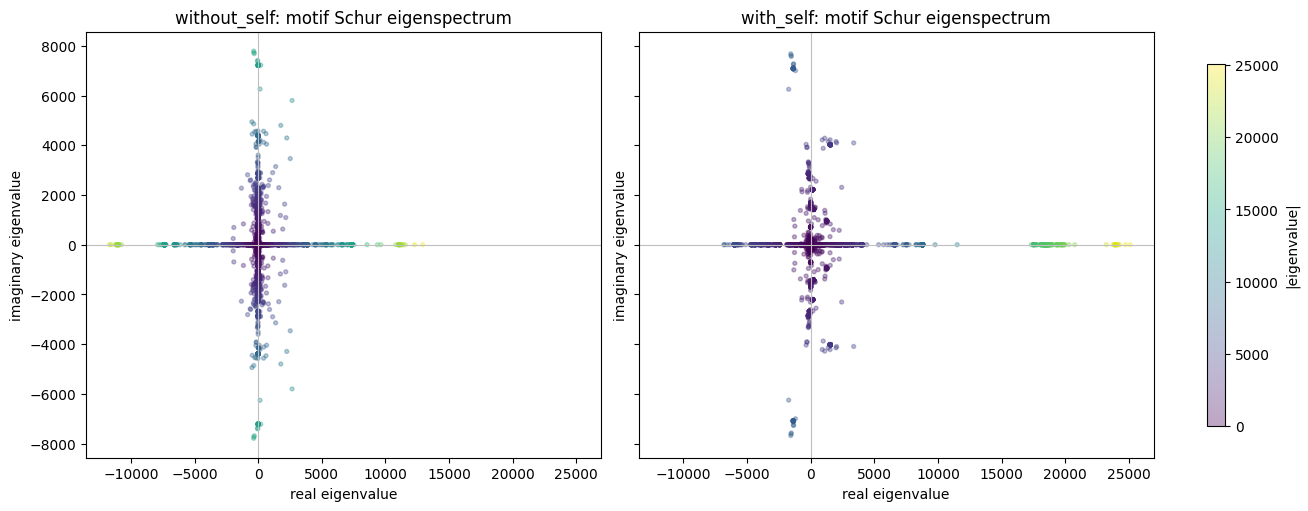

,scenario,motif_acronym,superpattern,eigenvalue_real,eigenvalue_imag,eigenvalue_abs
6000,with_self,EC-LI/II-MP | EC-LII/III-PT | MEC-LII-St,300,25110.0,0.0,25110.0
6003,with_self,EC-LI/II-MP | EC-LI/II-PFan | EC-LII/III-PT,300,24740.0,0.0,24740.0
6006,with_self,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-CxP,300,24270.0,0.0,24270.0
6009,with_self,EC-LI/II-MP | EC-LII/III-PT | LEC-LIII-CxP,300,24120.0,0.0,24120.0
6012,with_self,EC-LI/II-MP | EC-LII/III-PT | LEC-LIII-MPr,300,24120.0,0.0,24120.0
6015,with_self,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-BipCxP,300,24050.0,0.0,24050.0
6018,with_self,EC-LI/II-MP | EC-LII/III-PT | MEC-LII/III-PMul,300,24020.0,0.0,24020.0
6021,with_self,EC-LI/II-MP | EC-LII/III-PT | MEC-LV-P,300,23960.0,0.0,23960.0
6024,with_self,EC-LI/II-MP | EC-LII/III-PT | EC-LIII-PSt,210,23950.0,0.0,23950.0
6027,with_self,EC-LI/II-MP | EC-LII/III-PT | EC-LIII/V-BipP,210,23930.0,0.0,23930.0


In [4]:
spectrum=pd.concat([analysis.eigenspectrum_points(schur_no),analysis.eigenspectrum_points(schur_self)],ignore_index=True)
fig,axes=plt.subplots(1,2,figsize=(13,5),sharex=True,sharey=True,constrained_layout=True)
for scenario,ax in zip(["without_self","with_self"],axes):
    plot=spectrum[spectrum.scenario==scenario]
    scatter=ax.scatter(plot.eigenvalue_real,plot.eigenvalue_imag,c=plot.eigenvalue_abs,s=8,alpha=0.35,cmap="viridis")
    ax.axhline(0,color="0.75",linewidth=0.8); ax.axvline(0,color="0.75",linewidth=0.8)
    ax.set(title=f"{scenario}: motif Schur eigenspectrum",xlabel="real eigenvalue",ylabel="imaginary eigenvalue")
fig.colorbar(scatter,ax=axes,label="|eigenvalue|",shrink=0.85)
plt.show()
display(spectrum.nlargest(15,"eigenvalue_abs")[["scenario","motif_acronym","superpattern","eigenvalue_real","eigenvalue_imag","eigenvalue_abs"]])



## Ranked Schur modes across all motifs

This section expands every motif into its three Schur modes and ranks those individual modes globally. Unlike the motif-level table above, this printout asks which specific Schur modes are strongest, even when they are not the first row shown for a representative motif.


Top ranked Schur modes without self-weights


,global_schur_mode_rank,motif_index,motif_acronym,superpattern,schur_mode,eigenvalue_real,eigenvalue_imag,eigenvalue_abs,dominant_node_acronym,dominant_node_participation,schur_upper_coupling_in_abs
0,1,1786,EC-LI/II-MP | EC-LII/III-PT | MEC-LII-St,300,1,12928.711678,0.0,12928.711678,MEC-LII-St,0.474687,40573.980521
1,2,1761,EC-LI/II-MP | EC-LI/II-PFan | EC-LII/III-PT,300,1,12288.779734,0.0,12288.779734,EC-LII/III-PT,0.841363,34074.718213
2,3,1786,EC-LI/II-MP | EC-LII/III-PT | MEC-LII-St,300,3,-11685.309252,0.0,11685.309252,EC-LI/II-MP,0.891772,0.000000
3,4,1788,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-CxP,300,1,11573.202503,0.0,11573.202503,EC-LII/III-PT,0.611321,33022.543685
4,5,1761,EC-LI/II-MP | EC-LI/II-PFan | EC-LII/III-PT,300,3,-11553.656437,0.0,11553.656437,EC-LI/II-MP,0.685154,0.000000
5,6,1782,EC-LI/II-MP | EC-LII/III-PT | LEC-LIII-CxP,300,1,11385.888868,0.0,11385.888868,EC-LII/III-PT,0.604884,35912.566613
6,7,1783,EC-LI/II-MP | EC-LII/III-PT | LEC-LIII-MPr,300,1,11341.409241,0.0,11341.409241,EC-LII/III-PT,0.778669,28345.155601
7,8,1787,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-BipCxP,300,1,11230.615277,0.0,11230.615277,MEC-LIII-BipCxP,0.547432,49304.769733
8,9,1784,EC-LI/II-MP | EC-LII/III-PT | MEC-LII/III-PMul,300,1,11199.570851,0.0,11199.570851,EC-LII/III-PT,0.504615,40447.276799
9,10,1788,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-CxP,300,3,-11195.957248,0.0,11195.957248,EC-LI/II-MP,0.879907,0.000000


Top ranked Schur modes with self-weights


,global_schur_mode_rank,motif_index,motif_acronym,superpattern,schur_mode,eigenvalue_real,eigenvalue_imag,eigenvalue_abs,dominant_node_acronym,dominant_node_participation,schur_upper_coupling_in_abs
0,1,1786,EC-LI/II-MP | EC-LII/III-PT | MEC-LII-St,300,1,25114.365994,0.0,25114.365994,EC-LII/III-PT,0.427644,42059.916231
1,2,1761,EC-LI/II-MP | EC-LI/II-PFan | EC-LII/III-PT,300,1,24736.624557,0.0,24736.624557,EC-LII/III-PT,0.623280,33270.431910
2,3,1788,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-CxP,300,1,24266.728801,0.0,24266.728801,EC-LII/III-PT,0.525844,34694.324802
3,4,1782,EC-LI/II-MP | EC-LII/III-PT | LEC-LIII-CxP,300,1,24123.089526,0.0,24123.089526,EC-LII/III-PT,0.516254,38927.580131
4,5,1783,EC-LI/II-MP | EC-LII/III-PT | LEC-LIII-MPr,300,1,24117.000851,0.0,24117.000851,EC-LII/III-PT,0.600039,29466.992998
5,6,1787,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-BipCxP,300,1,24048.911802,0.0,24048.911802,MEC-LIII-BipCxP,0.401414,53170.366186
6,7,1784,EC-LI/II-MP | EC-LII/III-PT | MEC-LII/III-PMul,300,1,24017.422377,0.0,24017.422377,EC-LII/III-PT,0.466594,43485.862942
7,8,1791,EC-LI/II-MP | EC-LII/III-PT | MEC-LV-P,300,1,23960.181092,0.0,23960.181092,EC-LII/III-PT,0.635683,24838.050150
8,9,1778,EC-LI/II-MP | EC-LII/III-PT | EC-LIII-PSt,210,1,23952.731522,0.0,23952.731522,EC-LII/III-PT,0.502723,41371.923747
9,10,1780,EC-LI/II-MP | EC-LII/III-PT | EC-LIII/V-BipP,210,1,23934.115080,0.0,23934.115080,EC-LII/III-PT,0.620416,30279.639812


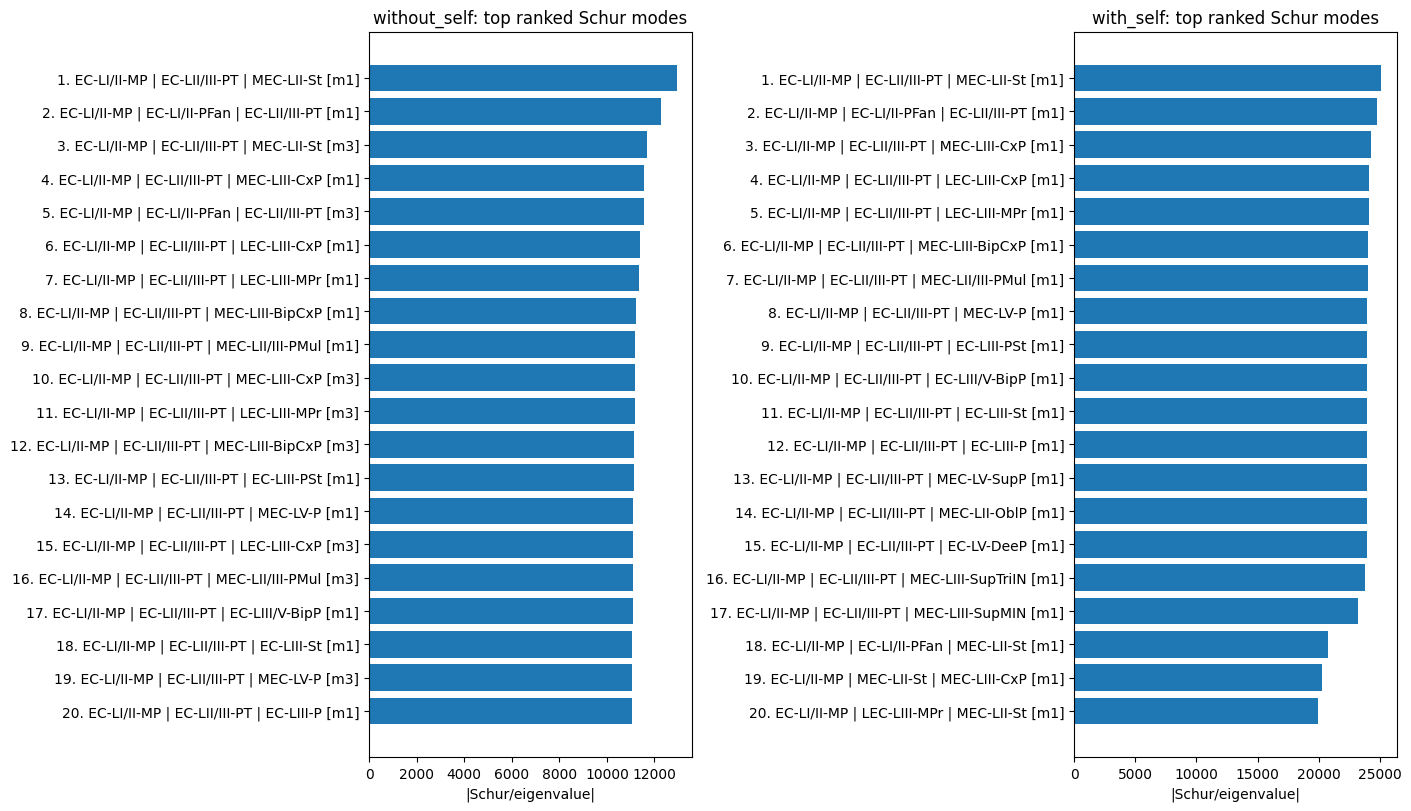

In [5]:
ranked_modes_no=analysis.rank_all_schur_modes(meta_no,blocks_no,"without_self",acronym_map=acronym_map)
ranked_modes_self=analysis.rank_all_schur_modes(meta_self,blocks_self,"with_self",acronym_map=acronym_map)
ranked_mode_columns=["global_schur_mode_rank","motif_index","motif_acronym","superpattern","schur_mode","eigenvalue_real","eigenvalue_imag","eigenvalue_abs","dominant_node_acronym","dominant_node_participation","schur_upper_coupling_in_abs"]
print("Top ranked Schur modes without self-weights")
display(ranked_modes_no.head(30)[ranked_mode_columns])
print("Top ranked Schur modes with self-weights")
display(ranked_modes_self.head(30)[ranked_mode_columns])
fig,axes=plt.subplots(1,2,figsize=(14,8),constrained_layout=True)
for title,frame,ax in [("without_self",ranked_modes_no,axes[0]),("with_self",ranked_modes_self,axes[1])]:
    plot=frame.head(20).iloc[::-1]
    labels=plot["global_schur_mode_rank"].astype(str)+". "+plot["motif_acronym"]+" [m"+plot["schur_mode"].astype(str)+"]"
    ax.barh(labels,plot["eigenvalue_abs"])
    ax.set(title=f"{title}: top ranked Schur modes",xlabel="|Schur/eigenvalue|",ylabel="")
plt.show()


## Motif enhancement and ablation testing

This section perturbs each enumerated motif locally. Enhancement multiplies the off-diagonal motif edges by `1 + MOTIF_ACTIVATION_GAIN` while preserving sign, so inhibitory edges become stronger inhibition. Ablation removes the off-diagonal motif edges. In the with-self scenario, diagonal self-weights remain present during ablation; in the no-self scenario, ablation leaves a zero 3x3 block.


Most activation-sensitive motifs without self-weights


,motif_index,motif_acronym,superpattern,baseline_spectral_radius,enhanced_spectral_radius,ablated_spectral_radius,enhancement_delta_spectral_radius,ablation_delta_spectral_radius,baseline_resolvent_gain_z1,enhanced_resolvent_gain_z1,ablated_resolvent_gain_z1,activation_sensitivity_score,removal_sensitivity_score
0,961,CA1-PerPatAss.2 | CA1-P | CA3c-P,030T,0.0,0.0,0.0,0.0,0.0,1.471994e+09,3.311277e+09,1.0,1.839283e+09,1.471994e+09
1,993,CA1-PerPatAss.2 | CA1-TriLam | CA3-P,030T,0.0,0.0,0.0,0.0,0.0,7.455948e+08,1.677735e+09,1.0,9.321405e+08,7.455948e+08
2,1720,DG-Gr | DG-HilEctGr | MEC-LV-P,030T,0.0,0.0,0.0,0.0,0.0,2.403198e+08,5.407167e+08,1.0,3.003970e+08,2.403198e+08
3,275,CA1-Bas | CA1-TriLam | CA3-P,030T,0.0,0.0,0.0,0.0,0.0,2.359884e+08,5.309985e+08,1.0,2.950101e+08,2.359884e+08
4,353,CA1-BasCCK | CA1-TriLam | CA3-P,030T,0.0,0.0,0.0,0.0,0.0,2.142397e+08,4.820496e+08,1.0,2.678099e+08,2.142397e+08
5,8,CA1-AxAxo | CA1-BasCCK | CA3c-P,030T,0.0,0.0,0.0,0.0,0.0,2.097165e+08,4.719762e+08,1.0,2.622596e+08,2.097165e+08
6,610,CA1-LMR | CA1-TriLam | CA3-P,030T,0.0,0.0,0.0,0.0,0.0,1.969706e+08,4.431892e+08,1.0,2.462186e+08,1.969706e+08
7,960,CA1-PerPatAss.2 | CA1-P | CA3-P,030T,0.0,0.0,0.0,0.0,0.0,1.902965e+08,4.280189e+08,1.0,2.377223e+08,1.902965e+08
8,508,CA1-HorBas | CA1-TriLam | CA3-P,030T,0.0,0.0,0.0,0.0,0.0,1.816786e+08,4.088610e+08,1.0,2.271824e+08,1.816786e+08
9,395,CA1-Bi | CA1-PerPatAss.2 | CA3c-P,030T,0.0,0.0,0.0,0.0,0.0,1.804339e+08,4.066858e+08,1.0,2.262518e+08,1.804339e+08


Most activation-sensitive motifs with self-weights


,motif_index,motif_acronym,superpattern,baseline_spectral_radius,enhanced_spectral_radius,ablated_spectral_radius,enhancement_delta_spectral_radius,ablation_delta_spectral_radius,baseline_resolvent_gain_z1,enhanced_resolvent_gain_z1,ablated_resolvent_gain_z1,activation_sensitivity_score,removal_sensitivity_score
0,1719,DG-Gr | DG-HilEctGr | MEC-LII-St,030T,0.921381,0.921381,0.921381,0.000000,0.000000,2.386152e+08,5.368814e+08,12.719585,2.982663e+08,2.386152e+08
1,1717,DG-Gr | DG-HilEctGr | EC-LI/II-PFan,030T,370.754461,370.754461,370.754461,0.000000,0.000000,5.824821e+06,1.309483e+07,12.719585,7.270011e+06,5.824808e+06
2,1720,DG-Gr | DG-HilEctGr | MEC-LV-P,030T,565.244728,565.244728,565.244728,0.000000,0.000000,5.426860e+06,1.219862e+07,12.719585,6.771755e+06,5.426847e+06
3,1715,DG-Gr | DG-HilEctGr | DG-SemiGr,030T,40.604694,40.604694,40.604694,0.000000,0.000000,3.952425e+06,8.875701e+06,12.719585,4.923276e+06,3.952412e+06
4,1718,DG-Gr | DG-HilEctGr | EC-LII/III-PT,030T,2277.297842,2277.297842,2277.297842,0.000000,0.000000,5.072360e+05,1.007724e+06,12.719585,5.004875e+05,5.072233e+05
5,1365,CA3-AxAxo | DG-Gr | DG-HilEctGr,030T,0.921381,0.921381,0.921381,0.000000,0.000000,3.936084e+05,6.998377e+05,12.719585,3.062293e+05,3.935957e+05
6,1436,CA3-LucORA | DG-Gr | DG-HilEctGr,030T,1.195062,1.195062,1.195062,0.000000,0.000000,3.877039e+05,6.861464e+05,12.719585,2.984424e+05,3.876912e+05
7,1351,CA3-AxAxo | CA3-Gr | MEC-LII-St,030T,0.000000,0.000000,0.000000,0.000000,0.000000,1.725089e+05,3.755636e+05,1.000000,2.030546e+05,1.725079e+05
8,1386,CA3-Bas | DG-Gr | DG-HilEctGr,030T,1688.150222,1688.150222,1688.150222,0.000000,0.000000,3.194488e+05,4.791733e+05,12.719585,1.597245e+05,3.194361e+05
9,1423,CA3-LMRTar | DG-Gr | DG-HilEctGr,030T,329.750083,329.750083,329.750083,0.000000,0.000000,3.194487e+05,4.791731e+05,12.719585,1.597244e+05,3.194360e+05


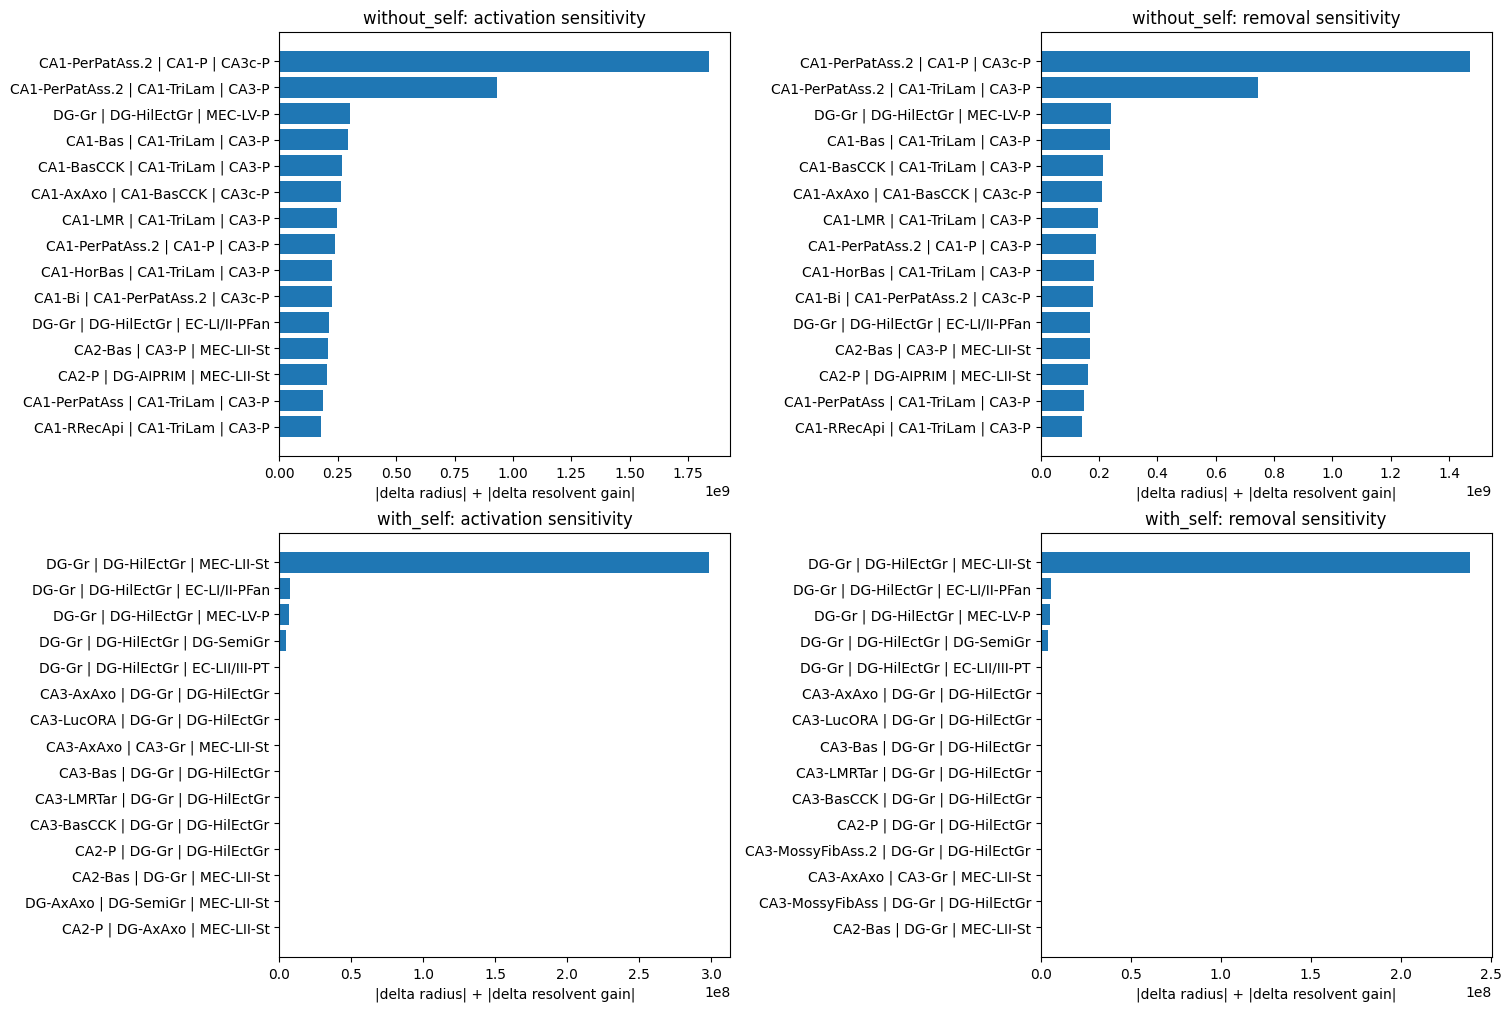

In [6]:
perturb_no=analysis.enhancement_ablation_test(meta_no,blocks_no,"without_self",activation_gain=MOTIF_ACTIVATION_GAIN,acronym_map=acronym_map)
perturb_self=analysis.enhancement_ablation_test(meta_self,blocks_self,"with_self",activation_gain=MOTIF_ACTIVATION_GAIN,acronym_map=acronym_map)
perturb_columns=["motif_index","motif_acronym","superpattern","baseline_spectral_radius","enhanced_spectral_radius","ablated_spectral_radius","enhancement_delta_spectral_radius","ablation_delta_spectral_radius","baseline_resolvent_gain_z1","enhanced_resolvent_gain_z1","ablated_resolvent_gain_z1","activation_sensitivity_score","removal_sensitivity_score"]
print("Most activation-sensitive motifs without self-weights")
display(perturb_no.head(25)[perturb_columns])
print("Most activation-sensitive motifs with self-weights")
display(perturb_self.head(25)[perturb_columns])
fig,axes=plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
for frame,title,row in [(perturb_no,"without_self",0),(perturb_self,"with_self",1)]:
    activation_plot=frame.nlargest(15,"activation_sensitivity_score").iloc[::-1]
    axes[row,0].barh(activation_plot["motif_acronym"],activation_plot["activation_sensitivity_score"])
    axes[row,0].set(title=f"{title}: activation sensitivity",xlabel="|delta radius| + |delta resolvent gain|")
    removal_plot=frame.nlargest(15,"removal_sensitivity_score").iloc[::-1]
    axes[row,1].barh(removal_plot["motif_acronym"],removal_plot["removal_sensitivity_score"])
    axes[row,1].set(title=f"{title}: removal sensitivity",xlabel="|delta radius| + |delta resolvent gain|")
plt.show()


## Enumerated Schur modes for representative motifs

This printout expands the top-ranked motif into its three Schur modes. Each row lists one mode, its eigenvalue, the dominant cell-type acronym, participation across the three cells, and the amount of upper-triangular coupling that mode receives from the Schur modes later in the pinned diagonal order. (Direction corrected 2026-09-17: blocks are analysed as `[post, pre]`, so row `m` of `T` is drive *into* mode `m`. The column was named `..._out_abs` and described as coupling out of the mode, which is the transpose of what it computes.)


In [7]:
TOP_MOTIF_INDEX=int(schur_no.iloc[0].motif_index)
mode_source,block_preview,mode_table,triangular_T=analysis.enumerate_schur_modes(meta_no,blocks_no,TOP_MOTIF_INDEX,acronym_map=acronym_map)
print("Representative motif index:",TOP_MOTIF_INDEX)
print("Full motif:",mode_source.nodes)
print("Abbreviated motif:"," | ".join([acronym_map[mode_source.node_1],acronym_map[mode_source.node_2],acronym_map[mode_source.node_3]]))
print("Superpattern letter:",mode_source.superpattern_letter)
print("3x3 no-self block used for Schur decomposition")
display(block_preview)
print("Enumerated Schur modes")
display(mode_table)
print("Complex Schur triangular matrix T")
display(triangular_T)


Representative motif index: 1786
Full motif: EC LI II Multipolar Pyramidal | EC LII III Pyramidal Tripolar | MEC LII Stellate
Abbreviated motif: EC-LI/II-MP | EC-LII/III-PT | MEC-LII-St
Superpattern letter: O
3x3 no-self block used for Schur decomposition


,EC-LI/II-MP,EC-LII/III-PT,MEC-LII-St
EC-LI/II-MP,0.000000,4216.395704,1179.869599
EC-LII/III-PT,28854.492388,0.000000,779.069273
MEC-LII-St,24134.530016,3189.046055,0.000000


Enumerated Schur modes


,mode,eigenvalue_real,eigenvalue_imag,eigenvalue_abs,dominant_node,dominant_node_acronym,EC-LI/II-MP_participation,EC-LII/III-PT_participation,MEC-LII-St_participation,upper_triangular_coupling_in_abs
0,1,12928.711678,0.0,12928.711678,MEC LII Stellate,MEC-LII-St,0.078842,0.446471,0.474687,40573.980521
1,2,-1243.402426,0.0,1243.402426,MEC LII Stellate,MEC-LII-St,0.029386,0.450774,0.519840,2313.790651
2,3,-11685.309252,0.0,11685.309252,EC LI II Multipolar Pyramidal,EC-LI/II-MP,0.891772,0.102755,0.005473,0.000000


Complex Schur triangular matrix T


,mode_1,mode_2,mode_3
mode_1,12928.711678+ 0.000000j,-7811.360892+ 0.000000j,-32762.619630+ 0.000000j
mode_2,0.000000+ 0.000000j,-1243.402426+ 0.000000j,2313.790651+ 0.000000j
mode_3,0.000000+ 0.000000j,0.000000+ 0.000000j,-11685.309252+ 0.000000j


## Motif-index matrix decomposition

This section treats each enumerated 3-node motif as a single indexed unit. The matrix rows are `motif_index` values and the columns are cell types; a motif places its Schur strength into the three columns for the cell types it contains. Decomposing this motif-index matrix asks which groups of motif occurrences co-vary through shared cell-type composition and Schur strength.


In [8]:
motif_index_no=analysis.decompose_motif_index_matrix(
    schur_no,
    acronym_map=acronym_map,
    weight_column=MOTIF_INDEX_MATRIX_WEIGHT,
    normalize_rows=MOTIF_INDEX_NORMALIZE_ROWS,
    n_modes=MOTIF_INDEX_N_MODES,
)
motif_index_self=analysis.decompose_motif_index_matrix(
    schur_self,
    acronym_map=acronym_map,
    weight_column=MOTIF_INDEX_MATRIX_WEIGHT,
    normalize_rows=MOTIF_INDEX_NORMALIZE_ROWS,
    n_modes=MOTIF_INDEX_N_MODES,
)
print("without-self motif-index matrix:",motif_index_no["matrix"].shape)
print("with-self motif-index matrix:",motif_index_self["matrix"].shape)
display(motif_index_no["matrix"].iloc[:8,:12])
display(motif_index_no["modes"])


without-self motif-index matrix: (2000, 85)
with-self motif-index matrix: (2000, 85)


,CA1 Axo Axonic,CA1 Back Projection,CA1 Basket,CA1 Basket CCK+,CA1 Bistratified,CA1 Horizontal Axo Axonic,CA1 Horizontal Basket,CA1 Ivy,CA1 LMR,CA1 Neurogliaform,CA1 Neurogliaform Projecting,CA1 O LM
motif_index,,,,,,,,,,,,
1786,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1761,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1788,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1782,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1783,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1787,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1784,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1778,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,mode,singular_value,explained_energy_fraction,top_motif_index,top_motif_acronym,top_superpattern,top_cell_type,top_cell_acronym,top_motif_score,top_cell_loading
0,1,84836.252334,0.199758,1270,CA2-P | CA3-P | CA3c-P,300,CA3c Pyramidal,CA3c-P,-14563.157296,-0.688783
1,2,75152.300109,0.156757,1786,EC-LI/II-MP | EC-LII/III-PT | MEC-LII-St,300,EC LI II Multipolar Pyramidal,EC-LI/II-MP,19193.140218,0.780491
2,3,60620.698821,0.101996,1557,DG-AIPRIM | DG-Bas | DG-Gr,210,DG Granule,DG-Gr,-10568.802157,-0.830368
3,4,48497.221749,0.065279,166,CA1-BackProj | CA3-Bas | CA3-P,210,CA3 Pyramidal,CA3-P,6834.893585,0.821139
4,5,32598.382173,0.029494,1770,EC-LI/II-MP | EC-LI/II-PFan | MEC-LII-St,300,EC LII III Pyramidal Tripolar,EC-LII/III-PT,8108.280406,-0.648072
5,6,31898.809627,0.028242,1290,CA2-P | DG-AIPRIM | DG-Gr,120C,CA2 Pyramidal,CA2-P,-5769.046659,-0.562673
6,7,29729.575645,0.024531,1309,CA2-P | DG-Gr | DG-Mossy,120C,DG AIPRIM,DG-AIPRIM,6618.482695,-0.650620
7,8,25452.040641,0.017980,1786,EC-LI/II-MP | EC-LII/III-PT | MEC-LII-St,300,MEC LII Stellate,MEC-LII-St,-9520.363156,-0.651336
8,9,24165.705044,0.016208,1789,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-SupMIN,300,MEC LIII Superficial Multipolar Interneuron,MEC-LIII-SupMIN,8057.939134,0.797965
9,10,22213.144259,0.013695,1285,CA2-P | CA3c-P | DG-Mossy,120U,DG Mossy,DG-Mossy,3691.169400,0.462478


## Motif-index singular spectrum and mode printout

The singular values summarize how many independent motif-index patterns are needed to explain the matrix. The mode printout lists the motif indices and cell types that contribute most strongly to the leading latent motif-index modes.


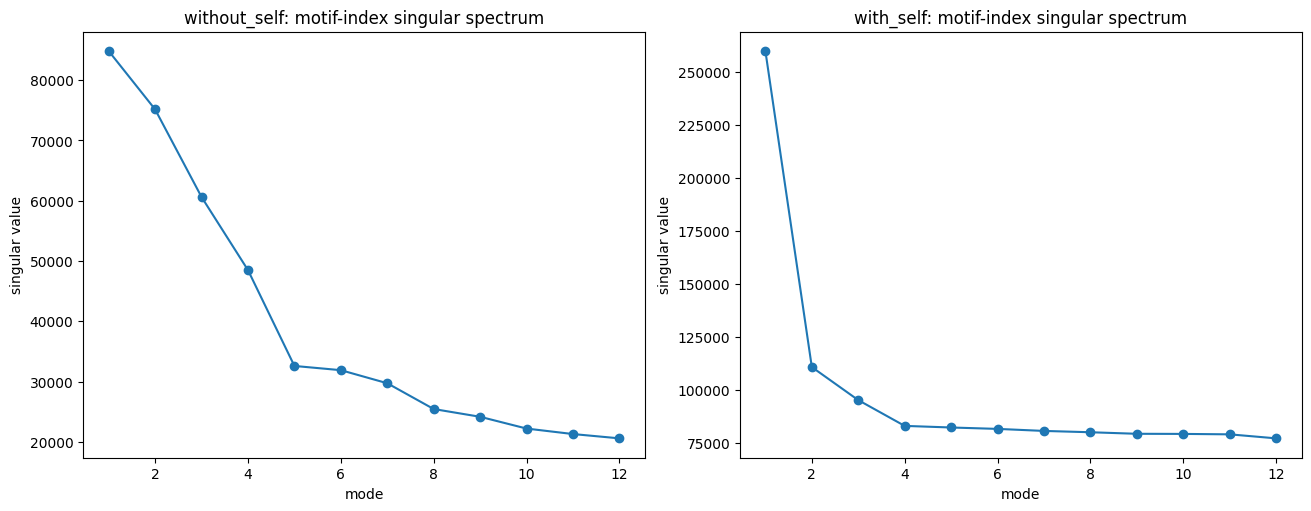

Top motif-index contributors, without self-weights


,mode,rank,motif_index,motif_acronym,nodes,superpattern,motif_score,abs_motif_score,spectral_radius
0,1,1,1270,CA2-P | CA3-P | CA3c-P,CA2 Pyramidal | CA3 Pyramidal | CA3c Pyramidal,300,-14563.157296,14563.157296,9640.176514
1,1,2,1279,CA2-P | CA3c-P | DG-Gr,CA2 Pyramidal | CA3c Pyramidal | DG Granule,210,-12917.004511,12917.004511,8553.467497
2,1,3,1245,CA2-P | CA3-Bas | CA3c-P,CA2 Pyramidal | CA3 Basket | CA3c Pyramidal,210,-10996.870482,10996.870482,7903.402840
3,1,4,1249,CA2-P | CA3-BasCCK | CA3c-P,CA2 Pyramidal | CA3 Basket CCK+ | CA3c Pyramidal,210,-10564.002019,10564.002019,7605.418037
4,1,5,159,CA1-BackProj | CA2-P | CA3c-P,CA1 Back Projection | CA2 Pyramidal | CA3c Pyramidal,210,-10535.664256,10535.664256,7388.741455
5,1,6,1276,CA2-P | CA3c-P | DG-AIPRIM,CA2 Pyramidal | CA3c Pyramidal | DG AIPRIM,120U,-10492.718957,10492.718957,7350.753723
6,1,7,1285,CA2-P | CA3c-P | DG-Mossy,CA2 Pyramidal | CA3c Pyramidal | DG Mossy,120U,-10371.761608,10371.761608,7350.753723
7,1,8,1208,CA2-Bas | CA2-P | CA3c-P,CA2 Basket | CA2 Pyramidal | CA3c Pyramidal,210,-10277.656115,10277.656115,7413.308068
8,1,9,1260,CA2-P | CA3-MossyFibAss | CA3c-P,CA2 Pyramidal | CA3 Mossy Fiber Associated | CA3c Pyramidal,210,-10227.981683,10227.981683,7357.088528
9,1,10,1263,CA2-P | CA3-MossyFibAss.2 | CA3c-P,CA2 Pyramidal | CA3 Mossy Fiber Associated ORDEN | CA3c Pyramidal,210,-10225.259240,10225.259240,7355.114672


Top cell loadings, without self-weights


,mode,rank,cell_type,cell_type_acronym,cell_loading,abs_cell_loading
0,1,1,CA3c Pyramidal,CA3c-P,-0.688783,0.688783
1,1,2,CA2 Pyramidal,CA2-P,-0.682247,0.682247
2,1,3,CA3 Pyramidal,CA3-P,-0.139644,0.139644
3,1,4,DG Granule,DG-Gr,-0.139119,0.139119
4,1,5,DG AIPRIM,DG-AIPRIM,-0.056405,0.056405
5,1,6,CA1 Back Projection,CA1-BackProj,-0.054878,0.054878
6,1,7,DG Mossy,DG-Mossy,-0.039950,0.039950
7,1,8,CA2 Wide Arbor Basket,CA2-WidArbBas,-0.036240,0.036240
8,1,9,CA3 Basket,CA3-Bas,-0.020380,0.020380
9,1,10,CA1 Pyramidal,CA1-P,-0.019830,0.019830


Top motif-index contributors, with self-weights


,mode,rank,motif_index,motif_acronym,nodes,superpattern,motif_score,abs_motif_score,spectral_radius
0,1,1,1786,EC-LI/II-MP | EC-LII/III-PT | MEC-LII-St,EC LI II Multipolar Pyramidal | EC LII III Pyramidal Tripolar | MEC LII Stellate,300,-29900.512240,29900.512240,25114.365994
1,1,2,1761,EC-LI/II-MP | EC-LI/II-PFan | EC-LII/III-PT,EC LI II Multipolar Pyramidal | EC LI II Pyramidal Fan | EC LII III Pyramidal Tripolar,300,-29187.209020,29187.209020,24736.624557
2,1,3,1788,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-CxP,EC LI II Multipolar Pyramidal | EC LII III Pyramidal Tripolar | MEC LIII Complex Pyramidal,300,-28897.900271,28897.900271,24266.728801
3,1,4,1783,EC-LI/II-MP | EC-LII/III-PT | LEC-LIII-MPr,EC LI II Multipolar Pyramidal | EC LII III Pyramidal Tripolar | LEC LIII Multipolar Principal,300,-28499.174661,28499.174661,24117.000851
4,1,5,1782,EC-LI/II-MP | EC-LII/III-PT | LEC-LIII-CxP,EC LI II Multipolar Pyramidal | EC LII III Pyramidal Tripolar | LEC LIII Complex Pyramidal,300,-28499.058564,28499.058564,24123.089526
5,1,6,1787,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-BipCxP,EC LI II Multipolar Pyramidal | EC LII III Pyramidal Tripolar | MEC LIII Bipolar Complex Pyramidal,300,-28408.911762,28408.911762,24048.911802
6,1,7,1784,EC-LI/II-MP | EC-LII/III-PT | MEC-LII/III-PMul,EC LI II Multipolar Pyramidal | EC LII III Pyramidal Tripolar | MEC LII III Pyramidal Multiform,300,-28359.693928,28359.693928,24017.422377
7,1,8,1777,EC-LI/II-MP | EC-LII/III-PT | EC-LIII-P,EC LI II Multipolar Pyramidal | EC LII III Pyramidal Tripolar | EC LIII Pyramidal,210,-28068.552133,28068.552133,23921.149825
8,1,9,1779,EC-LI/II-MP | EC-LII/III-PT | EC-LIII-St,EC LI II Multipolar Pyramidal | EC LII III Pyramidal Tripolar | EC LIII Stellate,210,-27945.425733,27945.425733,23932.922348
9,1,10,1790,EC-LI/II-MP | EC-LII/III-PT | MEC-LIII-SupTriIN,EC LI II Multipolar Pyramidal | EC LII III Pyramidal Tripolar | MEC LIII Superficial Trilayered Interneuron,300,-27856.887463,27856.887463,23778.629268


Top cell loadings, with self-weights


,mode,rank,cell_type,cell_type_acronym,cell_loading,abs_cell_loading
0,1,1,EC LI II Multipolar Pyramidal,EC-LI/II-MP,-0.901617,0.901617
1,1,2,EC LII III Pyramidal Tripolar,EC-LII/III-PT,-0.172871,0.172871
2,1,3,MEC LIII Complex Pyramidal,MEC-LIII-CxP,-0.116357,0.116357
3,1,4,MEC LII Stellate,MEC-LII-St,-0.116086,0.116086
4,1,5,LEC LIII Multipolar Principal,LEC-LIII-MPr,-0.107217,0.107217
5,1,6,LEC LIII Complex Pyramidal,LEC-LIII-CxP,-0.106914,0.106914
6,1,7,MEC LIII Bipolar Complex Pyramidal,MEC-LIII-BipCxP,-0.106810,0.106810
7,1,8,MEC LII III Pyramidal Multiform,MEC-LII/III-PMul,-0.106309,0.106309
8,1,9,EC LI II Pyramidal Fan,EC-LI/II-PFan,-0.105431,0.105431
9,1,10,EC LIII Pyramidal,EC-LIII-P,-0.098890,0.098890


In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for title,result,ax in [("without_self",motif_index_no,axes[0]),("with_self",motif_index_self,axes[1])]:
    values=result["singular_values"][:MOTIF_INDEX_N_MODES]
    ax.plot(range(1,len(values)+1),values,marker="o")
    ax.set(title=f"{title}: motif-index singular spectrum",xlabel="mode",ylabel="singular value")
plt.show()
print("Top motif-index contributors, without self-weights")
display(motif_index_no["motif_participation"].query("mode <= 3 and rank <= 10"))
print("Top cell loadings, without self-weights")
display(motif_index_no["cell_loadings"].query("mode <= 3 and rank <= 10"))
print("Top motif-index contributors, with self-weights")
display(motif_index_self["motif_participation"].query("mode <= 3 and rank <= 10"))
print("Top cell loadings, with self-weights")
display(motif_index_self["cell_loadings"].query("mode <= 3 and rank <= 10"))


## Superpattern-level rankings

These summaries aggregate the occurrence-level decompositions by Rees superpattern. High mean spectral radius indicates motif classes with strong local modes; high Schur off-diagonal norm or departure ratio indicates motifs whose local influence may depend on directional, non-normal mode coupling rather than eigenvalues alone.

,scenario,superpattern,superpattern_letter,canonical_motif_id,occurrence_count,mean_spectral_radius,max_spectral_radius,mean_schur_offdiag_norm,max_schur_offdiag_norm,mean_departure_ratio,max_departure_ratio,mean_dominant_participation
0,without_self,300,O,63,232,2.608169e+03,1.292871e+04,49402.293403,4.107462e+05,0.978657,0.999999,0.896217
1,without_self,210,N,31,363,2.441693e+03,1.113007e+04,57590.275265,1.238228e+06,0.985840,0.999999,0.908350
2,without_self,120U,L,23,283,2.209310e+03,1.103005e+04,122527.110791,1.238577e+06,0.990081,1.000000,0.903437
3,without_self,120C,M,27,93,1.977103e+03,7.350875e+03,91923.152782,1.227468e+06,0.990348,1.000000,0.963541
4,without_self,201,J,15,96,1.618277e+03,7.355462e+03,23993.056302,4.084758e+05,0.969137,0.999948,0.874120
5,without_self,030C,I,25,4,5.766402e+02,1.535944e+03,49022.323923,5.893504e+04,0.999680,1.000000,0.925466
6,without_self,120D,K,30,395,5.421746e+02,7.213181e+03,176689.653960,1.240563e+06,0.999552,1.000000,0.926526
7,without_self,030T,H,21,534,2.025073e-15,2.485657e-13,209583.044989,1.243237e+06,1.000000,1.000000,1.000000
8,with_self,201,J,15,96,6.863922e+03,1.997207e+04,24046.891061,4.085393e+05,0.865828,0.999009,0.756911
9,with_self,300,O,63,232,6.759077e+03,2.511437e+04,49532.096120,4.108046e+05,0.936429,0.999984,0.792671


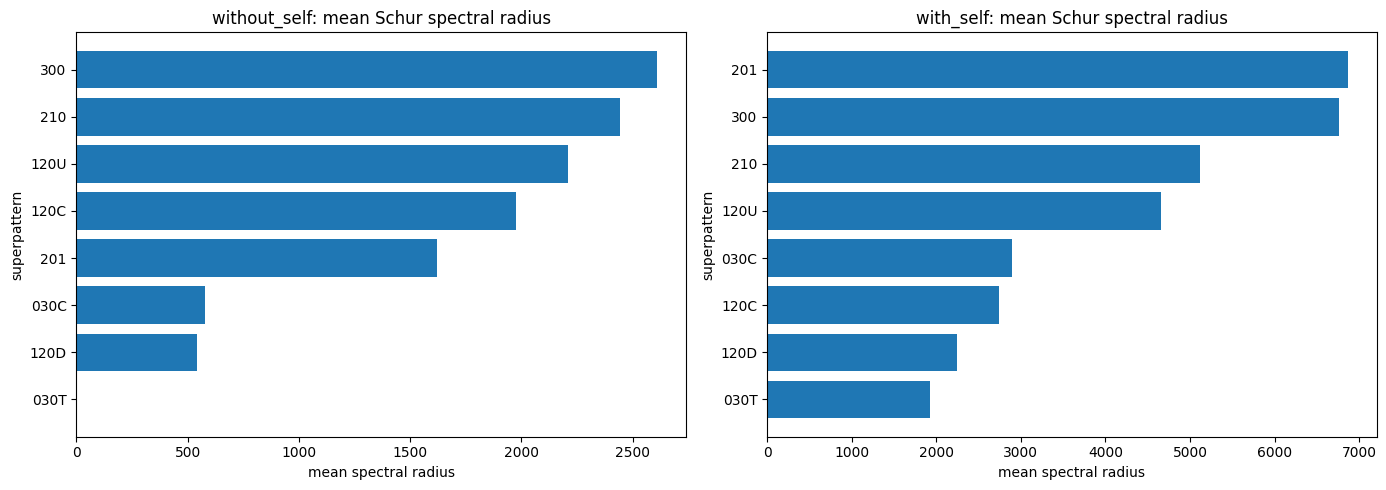

In [10]:
summary=pd.concat([analysis.summarize_by_superpattern(schur_no),analysis.summarize_by_superpattern(schur_self)],ignore_index=True)
display(summary)
fig,axes=plt.subplots(1,2,figsize=(14,5))
for scenario,ax in zip(["without_self","with_self"],axes):
    plot=summary[summary.scenario==scenario].sort_values("mean_spectral_radius")
    ax.barh(plot.superpattern,plot.mean_spectral_radius)
    ax.set(title=f"{scenario}: mean Schur spectral radius",xlabel="mean spectral radius",ylabel="superpattern")
fig.tight_layout(); plt.show()

## Self-weight sensitivity

This paired comparison aligns the same motif occurrence under no-self and with-self assumptions. Large changes identify motif subnetworks where diagonal self-weights materially change the local Schur spectrum or the degree of non-normal coupling.

,motif_acronym_without_self,superpattern,spectral_radius_without_self,spectral_radius_with_self,spectral_radius_change_from_self,schur_offdiag_norm_without_self,schur_offdiag_norm_with_self,schur_offdiag_change_from_self
0,EC-LI/II-MP | EC-LIII-PSt | MEC-LII-OblP,030T,0.000000,18296.078460,18296.078460,24575.367787,24575.367787,7.275958e-12
1,EC-LI/II-MP | EC-LIII-P | EC-LV-DeeP,030T,0.000000,18296.078460,18296.078460,24228.311197,24228.311197,-3.637979e-12
2,EC-LI/II-MP | EC-LIII-St | MEC-LII-OblP,030T,0.000000,18296.078460,18296.078460,33438.861200,33438.861200,-7.275958e-12
3,EC-LI/II-MP | EC-LIII-P | MEC-LII-OblP,030T,0.000000,18296.078460,18296.078460,28910.491238,28910.491238,-1.091394e-11
4,EC-LI/II-MP | EC-LIII-P | EC-LIII-St,120D,32.475295,18296.078460,18263.603165,37953.787743,37953.787743,1.455192e-11
5,EC-LI/II-MP | EC-LIII-St | EC-LIII/V-BipP,120D,76.324023,18296.078460,18219.754437,30029.011919,30029.011919,-2.910383e-11
6,EC-LI/II-MP | EC-LIII-P | EC-LIII/V-BipP,120D,102.429618,18296.078460,18193.648842,24887.154954,24887.154954,0.000000e+00
7,EC-LI/II-MP | EC-LIII-P | EC-LIII-PSt,120D,115.687190,18296.078460,18180.391270,30435.372027,30435.372027,-1.091394e-11
8,EC-LI/II-MP | EC-LIII-PSt | EC-LIII-St,120D,143.349222,18296.078460,18152.729238,34765.438976,34765.438976,-7.275958e-12
9,EC-LI/II-MP | EC-LIII-St | MEC-LV-SupP,210,315.855498,18298.905616,17983.050118,29372.665721,29374.277239,1.611518e+00


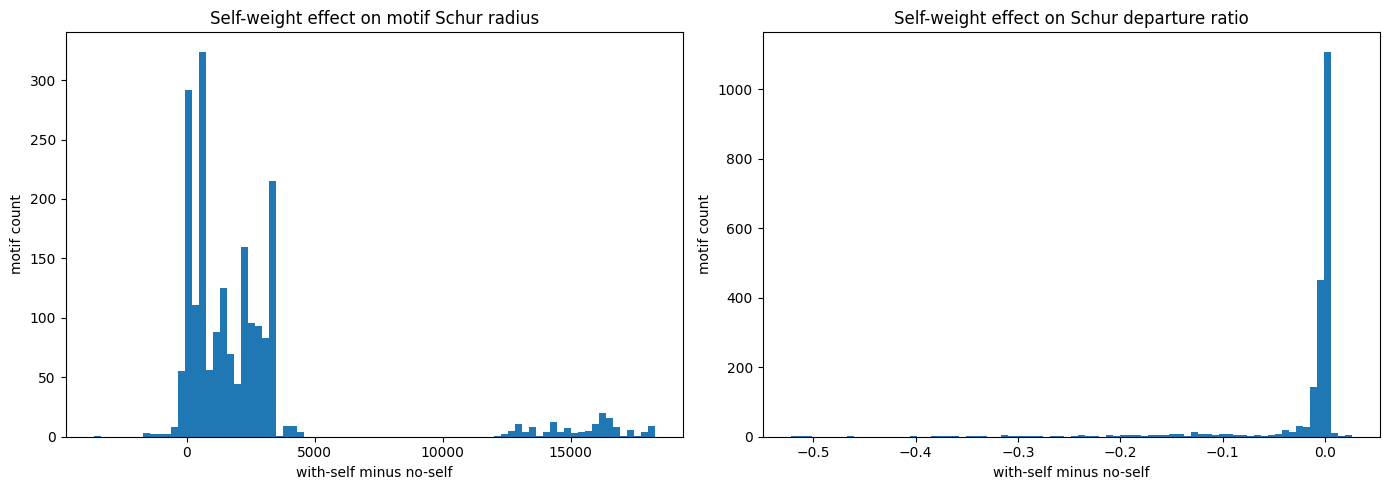

In [11]:
comparison=analysis.compare_self_scenarios(schur_no,schur_self)
display(comparison.head(25)[["motif_acronym_without_self","superpattern","spectral_radius_without_self","spectral_radius_with_self","spectral_radius_change_from_self","schur_offdiag_norm_without_self","schur_offdiag_norm_with_self","schur_offdiag_change_from_self"]])
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].hist(comparison.spectral_radius_change_from_self,bins=80)
axes[0].set(title="Self-weight effect on motif Schur radius",xlabel="with-self minus no-self",ylabel="motif count")
axes[1].hist(comparison.departure_ratio_change_from_self,bins=80)
axes[1].set(title="Self-weight effect on Schur departure ratio",xlabel="with-self minus no-self",ylabel="motif count")
fig.tight_layout(); plt.show()


## Cell-type pathways emphasized by Schur modes

This section asks which cell types repeatedly appear in the strongest motif Schur modes. Repeated dominant Schur-node appearances suggest candidate local pathway junctions, especially when those same cells were also highlighted by Green's influence or pathway consensus analyses.

In [12]:
cells_no=analysis.summarize_cells(schur_no,top_n=500)
cells_self=analysis.summarize_cells(schur_self,top_n=500)
cells_no.insert(1,"cell_type_acronym",cells_no.cell_type.map(acronym_map).fillna(cells_no.cell_type))
cells_self.insert(1,"cell_type_acronym",cells_self.cell_type.map(acronym_map).fillna(cells_self.cell_type))
print("Top cells without self-weights"); display(cells_no.head(25))
print("Top cells with self-weights"); display(cells_self.head(25))


Top cells without self-weights


,cell_type,cell_type_acronym,top_motif_mentions,dominant_schur_mentions
0,CA3c Pyramidal,CA3c-P,121,61
1,DG Granule,DG-Gr,123,46
2,CA3 Pyramidal,CA3-P,113,38
3,CA1 Back Projection,CA1-BackProj,50,31
4,MEC LIII Superficial Multipolar Interneuron,MEC-LIII-SupMIN,47,29
5,EC LI II Multipolar Pyramidal,EC-LI/II-MP,117,27
6,CA2 Wide Arbor Basket,CA2-WidArbBas,40,20
7,DG AIPRIM,DG-AIPRIM,35,19
8,DG Basket,DG-Bas,25,16
9,CA2 Pyramidal,CA2-P,104,15


Top cells with self-weights


,cell_type,cell_type_acronym,top_motif_mentions,dominant_schur_mentions
0,CA2 Pyramidal,CA2-P,100,38
1,EC LI II Multipolar Pyramidal,EC-LI/II-MP,147,32
2,EC LII III Pyramidal Tripolar,EC-LII/III-PT,37,30
3,MEC LII Stellate,MEC-LII-St,34,27
4,CA1 Back Projection,CA1-BackProj,46,26
5,DG Granule,DG-Gr,63,20
6,MEC LIII Superficial Multipolar Interneuron,MEC-LIII-SupMIN,94,17
7,MEC LIII Bipolar Complex Pyramidal,MEC-LIII-BipCxP,26,17
8,MEC LII III Pyramidal Multiform,MEC-LII/III-PMul,27,16
9,EC LI II Pyramidal Fan,EC-LI/II-PFan,34,15


## Exported results

The exported tables preserve the occurrence-level Schur modes, superpattern summaries, self-weight sensitivity table, and top-cell rankings for downstream pathway interpretation or follow-up decomposition.

In [13]:
exported=analysis.export_results(OUTPUT_DIR,schur_no,schur_self,summary,comparison,cells_no,cells_self)
acronyms.to_csv(OUTPUT_DIR/"cell_type_acronym_map.csv",index=False)
ranked_modes_no.to_csv(OUTPUT_DIR/"ranked_schur_modes_without_self.csv",index=False)
ranked_modes_self.to_csv(OUTPUT_DIR/"ranked_schur_modes_with_self.csv",index=False)
perturb_no.to_csv(OUTPUT_DIR/"motif_enhancement_ablation_without_self.csv",index=False)
perturb_self.to_csv(OUTPUT_DIR/"motif_enhancement_ablation_with_self.csv",index=False)
motif_index_no["matrix"].to_csv(OUTPUT_DIR/"motif_index_matrix_without_self.csv")
motif_index_self["matrix"].to_csv(OUTPUT_DIR/"motif_index_matrix_with_self.csv")
motif_index_no["modes"].to_csv(OUTPUT_DIR/"motif_index_modes_without_self.csv",index=False)
motif_index_self["modes"].to_csv(OUTPUT_DIR/"motif_index_modes_with_self.csv",index=False)
motif_index_no["motif_participation"].to_csv(OUTPUT_DIR/"motif_index_participation_without_self.csv",index=False)
motif_index_self["motif_participation"].to_csv(OUTPUT_DIR/"motif_index_participation_with_self.csv",index=False)
motif_index_no["cell_loadings"].to_csv(OUTPUT_DIR/"motif_index_cell_loadings_without_self.csv",index=False)
motif_index_self["cell_loadings"].to_csv(OUTPUT_DIR/"motif_index_cell_loadings_with_self.csv",index=False)
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.resolve())





/sessions/rcw-014rgwc3jmeqrbohxxdvfgoq/mnt/AscoliLab/tarjan_reorder/outputs/motif_schur_decomposition_analysis/cell_type_acronym_map.csv
/sessions/rcw-014rgwc3jmeqrbohxxdvfgoq/mnt/AscoliLab/tarjan_reorder/outputs/motif_schur_decomposition_analysis/motif_enhancement_ablation_with_self.csv
/sessions/rcw-014rgwc3jmeqrbohxxdvfgoq/mnt/AscoliLab/tarjan_reorder/outputs/motif_schur_decomposition_analysis/motif_enhancement_ablation_without_self.csv
/sessions/rcw-014rgwc3jmeqrbohxxdvfgoq/mnt/AscoliLab/tarjan_reorder/outputs/motif_schur_decomposition_analysis/motif_index_cell_loadings_with_self.csv
/sessions/rcw-014rgwc3jmeqrbohxxdvfgoq/mnt/AscoliLab/tarjan_reorder/outputs/motif_schur_decomposition_analysis/motif_index_cell_loadings_without_self.csv
/sessions/rcw-014rgwc3jmeqrbohxxdvfgoq/mnt/AscoliLab/tarjan_reorder/outputs/motif_schur_decomposition_analysis/motif_index_matrix_with_self.csv
/sessions/rcw-014rgwc3jmeqrbohxxdvfgoq/mnt/AscoliLab/tarjan_reorder/outputs/motif_schur_decomposition_analy

## Interpretation guide

A motif with a larger Schur spectral radius has a stronger local recurrent or directional mode after the global spectral-radius scaling already applied upstream. A motif with a larger Schur off-diagonal norm or departure ratio is more non-normal: its local pathways can transiently pass activity through the 3-node block even when eigenvalues alone look modest. Self-weight sensitivity should be interpreted as diagonal terms changing the local mode geometry, not as proof that the motif edges alone caused a global circuit effect.